# Support Vector Machine (SVM): Implementation and Comparison with MLP (Hinge Loss), K-NN and NCC

### **Purpose**
***
#

In this particular project we aim to implement a support vector machine (SVM) using various linear and non linear kernels, aside with different training parameters each time. The performances of the best models, based on their overall accuracy and generalization ability, will then be compared with an also to be implemented single hidden layer MLP (Hinge Loss), the K-NN method (for k=1 and k=3 neighbors) and the NCC algorithm. The latter two have been implemented in the previous project. Evaluations of the foretold models will be done using the CIFAR-10 dataset, same as in our previous work. Everything regarding the coding part is written in Pytorch. As for the hardware, we make use of the CPU or Google Colab's T4 GPU, depending on availability, so the running times may vary in each attempt.

#

### **Chosen Dataset**
***
#
The dataset used for this project is the CIFAR-10 dataset (taken from the following adress https://www.cs.toronto.edu/~kriz/cifar.html) and consists of 60.000 32x32 colour images in 10 classes (6.000 pics for each). It is divided into five training batches, each including 10.000 pictures in random order, and a test batch that contains 10.000 randomly-selected images from each class. Some training batches may contain more images from one class than another. The classes are completely mutually exclusive, and are the following: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck.

#

### **About the SVM**
***
#

The Support Vector Machine is a supervised machine learning algorithm used for classification and regression tasks. The model's target is to find the optimal hyperplane that maximally separates different classes in the feature space. Support vectors are training samples that lie on the margin boundaries, where margin is the distance between the closest points of different classes.  We will be trying linear kernels and non-linear kernels, such as RBF and polynomial, while also tuning parameters C (regularization) and γ along the process.

#

### **Project's Layout**
***
#

The project is mainly structured in the following order (sections):


1.   Imported modules' description
2.   Configurations - Device, SVM, MLP and Visuals
3.   Neural network models
4.   Data loading and preprocessing
5.   SVM training
6.   MLP training
7.   Results analysis and comparison
8.   Visualization
9.   Main execution
10.  Comparison with K-NN and NCC







## **1\. Imported Modules' Description**
******
#
The modules we will be using throughout the project are the following:

*  ***torch*** : The library that provides tensors (multi-dimensional arrays) and fundamental operations for deep learning.

*   ***torch.nn(as nn)*** : Contains building blocks for neural networks: layers, activation functions, loss functions, and the base nn.Module class.

*   ***torch.optim(as optim)*** : Provides optimization algorithms for training. Implements back-propagation algorithms to update network weights.

*   ***Dataloader*** : Loads data in batches, handles shuffling, and provides parallel processing. Facilitates iteration over training/test data efficiently.

*   ***TensorDataset*** : A simple PyTorch wrapper that pairs multiple tensors (features and labels) into a single dataset.

*   ***torchvision*** : Library for Computer Vision tasks. Contains ready-to-use datasets (like CIFAR-10 in this case), pre-trained models, and utility functions for image processing.

*   ***torchvision.transforms(as transforms)*** : Image preprocessing and augmentation tools. Includes operations like normalization, resizing, cropping, flipping, and conversion to tensors.

*  ***numpy*** : More precisely a library used for working with arrays which are way faster to process than lists. We treat the train and test data as arrays.

*   ***matplotlib.pyplot(as plt)*** : Plotting library for creating visualizations. Used to generate graphs, charts, and display images (loss curves, accuracy plots).

*   ***svm(from sklearn)*** : A scikit-learn module providing Support Vector Machine algorithms for classification. It supports various kernels (linear, RBF, polynomial) to find optimal decision boundaries in high-dimensional spaces.

*   ***PCA(from sklearn.decomposition)*** : A dimensionality reduction technique that transforms data into a lower-dimensional space by finding the directions (principal components) of maximum variance.

*   ***StandardScaler(from sklearn.preprocessing)*** : A preprocessing tool that standardizes features by removing the mean and scaling to unit variance (mean=0, std=1).

*   ***accuracy_score(from sklearn.metrics)*** : Returns the fraction of correctly classified samples.

*   ***classification_report(from sklearn.metrics)*** : Provides precision, recall, F1-score per class.

*   ***confusion_matrix(from sklearn.metrics)*** : Shows a matrix of true vs predicted labels to visualize classification errors.

*  ***time*** : We use certain functions of this module in order to measure the training and pediction time of each method.

*   ***datetime*** : Python's built-in module for working with dates and times. Used to format timestamps for logging training start/end times.


The related code follows:


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 1. Imported Modules
# ═══════════════════════════════════════════════════════════════════════════


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import time
from datetime import datetime

##  **2\. Configurations - Device, SVM, MLP and Visuals**
******
#
This section defines the Configuration class that centralizes all experiment parameters.
It includes device selection (CPU/GPU), dataset options (subset size, PCA components),
SVM configurations (multiple kernel types with varying C and gamma parameters), MLP
hyperparameters (hidden layer size, learning rate, dropout, early stopping), and
visualization settings. This design allows us easy experimentation by changing
parameters in one place without modifying the core code.


The related code follows:


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 2. CONFIGURATION SECTION
# ═══════════════════════════════════════════════════════════════════════════

class Config:
    """Main class for changing the parameters of the experiments."""

    # ─────────────────────────────────────────────────────────────────────
    # GENERAL SETTINGS
    # ─────────────────────────────────────────────────────────────────────

    # Device
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Dataset
    USE_SUBSET = False
    SUBSET_SIZE = 5000
    USE_PCA = True
    PCA_COMPONENTS = 100

    # Random seed for reproducibility
    RANDOM_SEED = 42

    # ─────────────────────────────────────────────────────────────────────
    # SVM CONFIGURATION
    # ─────────────────────────────────────────────────────────────────────

    SVM_EXPERIMENTS = [
        # Linear Kernel
        {
            'name': 'Linear SVM (C=0.1)',
            'kernel': 'linear',
            'C': 0.1,
            'gamma': 'scale',
            'degree': 3
        },
        {
            'name': 'Linear SVM (C=1.0)',
            'kernel': 'linear',
            'C': 1.0,
            'gamma': 'scale',
            'degree': 3
        },
        {
            'name': 'Linear SVM (C=10.0)',
            'kernel': 'linear',
            'C': 10.0,
            'gamma': 'scale',
            'degree': 3
        },

        # RBF Kernel
        {
            'name': 'RBF SVM (C=0.1, γ=scale)',
            'kernel': 'rbf',
            'C': 0.1,
            'gamma': 'scale',
            'degree': 3
        },
        {
            'name': 'RBF SVM (C=1.0, γ=scale)',
            'kernel': 'rbf',
            'C': 1.0,
            'gamma': 'scale',
            'degree': 3
        },
        {
            'name': 'RBF SVM (C=10.0, γ=scale)',
            'kernel': 'rbf',
            'C': 10.0,
            'gamma': 'scale',
            'degree': 3
        },
        {
            'name': 'RBF SVM (C=100.0, γ=scale)',
            'kernel': 'rbf',
            'C': 100.0,
            'gamma': 'scale',
            'degree': 3
        },

        # RBF με διαφορετικό gamma
        {
            'name': 'RBF SVM (C=1.0, γ=0.001)',
            'kernel': 'rbf',
            'C': 1.0,
            'gamma': 0.001,
            'degree': 3
        },
        {
            'name': 'RBF SVM (C=1.0, γ=0.01)',
            'kernel': 'rbf',
            'C': 1.0,
            'gamma': 0.01,
            'degree': 3
        },

        # Polynomial Kernel
        {
            'name': 'Polynomial SVM (degree=2, C=1.0)',
            'kernel': 'poly',
            'C': 1.0,
            'gamma': 'scale',
            'degree': 2
        },
        {
            'name': 'Polynomial SVM (degree=3, C=1.0)',
            'kernel': 'poly',
            'C': 1.0,
            'gamma': 'scale',
            'degree': 3
        },
        {
            'name': 'Polynomial SVM (degree=4, C=1.0)',
            'kernel': 'poly',
            'C': 1.0,
            'gamma': 'scale',
            'degree': 4
        },
    ]

    # ─────────────────────────────────────────────────────────────────────
    # MLP CONFIGURATION
    # ─────────────────────────────────────────────────────────────────────

    MLP_CONFIG = {
        'hidden_size': 128,         # Number of neurons in hidden layer
        'learning_rate': 0.001,     # Learning rate for Adam optimizer
        'epochs': 50,               # Training epochs
        'batch_size': 128,          # Batch size
        'dropout_rate': 0.0,        # Dropout rate
        'weight_decay': 0.0,        # L2 regularization
        'early_stopping': False,    # If True, stops if it does not get better
        'patience': 10,             # Number of epochs before stopping
    }

    # ─────────────────────────────────────────────────────────────────────
    # VISUALIZATION CONFIGURATION
    # ─────────────────────────────────────────────────────────────────────

    SHOW_CLASSIFICATION_EXAMPLES = True  # Show examples
    N_CORRECT_EXAMPLES = 5               # Show correct examples
    N_WRONG_EXAMPLES = 5                 # Show false examples

    SHOW_CONFUSION_MATRICES = True       # Show confusion matrices
    SHOW_MLP_TRAINING_CURVES = True      # Show training curves

    # ─────────────────────────────────────────────────────────────────────
    # PRINT CONFIGURATION
    # ─────────────────────────────────────────────────────────────────────

    VERBOSE = True                       # Detailed output
    SHOW_CLASSIFICATION_REPORT = True    # Show classification report


# ═══════════════════════════════════════════════════════════════════════════
# DEVICE CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════

device = Config.DEVICE
print(f"═══════════════════════════════════════════════════════════════")
print(f"Device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"═══════════════════════════════════════════════════════════════\n")

═══════════════════════════════════════════════════════════════
Device: cuda
GPU: Tesla T4
═══════════════════════════════════════════════════════════════



##  **3\. Neural Network Models**
******
#

The Neural Network Models section defines two custom classes, MLPHingeLoss() and MultiHingeLoss() using the nn.Module:

*  **MLPHingeLoss class** : it implements a simple neural network
with one hidden layer, ReLU activation, and optional dropout for regularization.

*  **MultiClassHingeLoss** : it is a custom loss function implementing the Crammer-Singer
multi-class hinge loss formulation,
which encourages the model to score the correct class higher than all incorrect
classes by at least a margin of 1.

The related code follows:


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 3. NEURAL NETWORK MODELS
# ═══════════════════════════════════════════════════════════════════════════

class MLPHingeLoss(nn.Module):
    """
    - Multi-Layer Perceptron with one hidden layer.
    - ReLU activation.
    - Dropout for regularization.
    - Output layer returns raw scores for each class.
    - Without softmax because Hinge Loss works with raw scores.
    """
    def __init__(self, input_size, hidden_size, num_classes, dropout_rate=0.0):
        super(MLPHingeLoss, self).__init__()

        # Input → Hidden
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)

        # Hidden → Output
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        """
        Args:
            x: Input tensor [batch_size, input_size]

        Returns:
            Output [batch_size, num_classes]
        """
        out = self.fc1(x)
        out = self.relu(out)
        out = self.dropout(out)
        out = self.fc2(out)
        return out


class MultiClassHingeLoss(nn.Module):
    """
    Multi-class Hinge Loss

    """
    def __init__(self, margin=1.0):
        super(MultiClassHingeLoss, self).__init__()
        self.margin = margin

    def forward(self, outputs, targets):
        """
        Args:
            outputs: Model predictions [batch_size, num_classes]
            targets: Ground truth labels [batch_size]

        Returns:
            Scalar loss value
        """
        batch_size = outputs.size(0)
        num_classes = outputs.size(1)

        # Correct class's score for each sample
        correct_class_scores = outputs[torch.arange(batch_size), targets]

        # Calculate margins: (score_wrong_class - score_correct_class + margin)
        margins = outputs - correct_class_scores.unsqueeze(1) + self.margin

        # Extract margin of correct class (making it equal to 0)
        margins[torch.arange(batch_size), targets] = 0

        # Hinge: max(0, margin)
        loss = torch.clamp(margins, min=0).sum(dim=1).mean()

        return loss

## **4\. Data loading and preprocessing**
***
#

In the current section, we handle downloading the CIFAR-10 dataset via torchvision.datasets.CIFAR10 and preparing it for both SVM and MLP models. We flatten the 32×32×3 images into 3072-dimensional vectors, normalize pixel values to [0,1] range, and apply PCA for dimensionality reduction and StandardScaler for feature standardization. For the MLP, it wraps the data in TensorDataset and DataLoader objects to enable efficient batch-based training with shuffling.
#



The related code is shown later in the project:


##  **5\. SVM Training**
***
#

In the SVM Training part, we iterate through configured kernel experiments (linear, RBF, polynomial) using scikit-learn's SVC classifier. For each configuration, we train an SVM with specified hyperparameters (C, gamma, degree), measure training time, generate predictions on the test set, and calculate accuracy. Results including accuracy scores, training times, and trained models are stored for later comparison and visualization.

The related code is here


## **6\. MLP Training**
***
#

The ***train_mlp_hinge()*** method implements the complete training loop for the Multi-Layer
Perceptron using Hinge Loss. It converts data to PyTorch tensors, creates DataLoader for
mini-batch training, initializes the model with specified architecture, uses Adam optimizer
with optional L2 regularization, trains for specified epochs while monitoring both training
and test accuracy, implements optional early stopping when test accuracy stops improving,
and stores training curves (loss and accuracy) for visualization and analysis.

The related code is shown later in the project:

##  **7\. Results analysis and comparison**
***
#

In this section, two methods handle result analysis: ***compare_results()*** creates a comparative table showing
train/test accuracy, train-test gap, and training time for all models, identifies the best
performing model based on test accuracy. ***analyze_overfitting_underfitting()*** diagnoses each
model's fit quality by examining the train-test gap: classifies models as underfitting
(both accuracies < 45%), overfitting (gap > 15%), slight overfitting (gap 8-15%), or
good fit (gap < 8%), and provides explanations for each diagnosis.

The related code is shown later in the project:

## **8\. Visualization**
***
#
Contains three visualization methods: ***show_classification_examples()*** displays sample images
with their true and predicted labels for both correct and incorrect classifications, helping
identify patterns in model errors. ***plot_confusion_matrices()*** creates heatmaps showing the
confusion between different classes for each model. ***plot_mlp_training_curves()*** plots the
training loss and accuracy evolution over epochs, showing both training and test performance
to visualize learning dynamics and detect overfitting.


The related code is shown later in the project:

##  **9\. Main Execution**
***
#
This part of the project calls the data loading, trains all SVM configurations and the MLP model, collects results, performs comparative analysis, and generates visualizations. It also coordinates the workflow, handles timing measurements, and ensures all components execute in the correct order while printing progress updates throughout the process.

The related code is shown later in the project:





╔══════════════════════════════════════════════════════════════════════════════╗
║               CIFAR-10 CLASSIFICATION EXPERIMENT                             ║
║                    SVM vs MLP (Hinge Loss)                                   ║
╚══════════════════════════════════════════════════════════════════════════════╝

DATA LOADING & PREPROCESSING

Download CIFAR-10 dataset...
 Training samples: 50000
 Test samples: 10000
 Features: 3072 (32×32×3)
 Number of classes: 10

Classes distribution:
  0. airplane    : Train=5000, Test=1000
  1. automobile  : Train=5000, Test=1000
  2. bird        : Train=5000, Test=1000
  3. cat         : Train=5000, Test=1000
  4. deer        : Train=5000, Test=1000
  5. dog         : Train=5000, Test=1000
  6. frog        : Train=5000, Test=1000
  7. horse       : Train=5000, Test=1000
  8. ship        : Train=5000, Test=1000
  9. truck       : Train=5000, Test=1000

Normalization (StandardScaler)...
 Mean ≈ 0, Std ≈ 1

Apply PCA: 100 components
 Vari

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Calculate predictions...

────────────────────────────────────────────────────────────────────────────────
RESULTS:
  Training Time: 30.97 sec
  Training Accuracy: 17.81%
  Test Accuracy: 17.15%
  Support Vectors: 23704
────────────────────────────────────────────────────────────────────────────────

Classification Report:
              precision    recall  f1-score   support

    airplane       0.09      0.01      0.02      1000
  automobile       0.18      0.09      0.12      1000
        bird       0.11      0.05      0.07      1000
         cat       0.14      0.11      0.12      1000
        deer       0.09      0.05      0.06      1000
         dog       0.18      0.16      0.17      1000
        frog       0.19      0.27      0.22      1000
       horse       0.13      0.26      0.17      1000
        ship       0.26      0.41      0.32      1000
       truck       0.18      0.32      0.23      1000

    accuracy                           0.17     10000
   macro avg       0.15  

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Calculate predictions...

────────────────────────────────────────────────────────────────────────────────
RESULTS:
  Training Time: 31.01 sec
  Training Accuracy: 17.58%
  Test Accuracy: 16.99%
  Support Vectors: 23701
────────────────────────────────────────────────────────────────────────────────

Classification Report:
              precision    recall  f1-score   support

    airplane       0.08      0.01      0.02      1000
  automobile       0.18      0.09      0.12      1000
        bird       0.11      0.05      0.07      1000
         cat       0.13      0.11      0.12      1000
        deer       0.09      0.05      0.06      1000
         dog       0.18      0.17      0.17      1000
        frog       0.19      0.22      0.20      1000
       horse       0.13      0.28      0.18      1000
        ship       0.26      0.39      0.31      1000
       truck       0.18      0.32      0.23      1000

    accuracy                           0.17     10000
   macro avg       0.15  

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


... (15 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Calculate predictions...

────────────────────────────────────────────────────────────────────────────────
RESULTS:
  Training Time: 46.53 sec
  Training Accuracy: 22.79%
  Test Accuracy: 18.70%
  Support Vectors: 24173
────────────────────────────────────────────────────────────────────────────────

Classification Report:
              precision    recall  f1-score   support

    airplane       0.65      0.12      0.20      1000
  automobile       0.67      0.12      0.21      1000
        bird       0.36      0.04      0.06      1000
         cat       0.34      0.04      0.08      1000
        deer       0.28      0.03      0.06      1000
         dog       0.41      0.12      0.19      1000
        frog       0.36      0.19      0.25      1000
       horse       0.28      0.10      0.14      1000
        ship       0.30      0.21      0.25      1000
       truck       0.12      0.91      0.21      1000

    accuracy                           0.19     10000
   macro avg       0.38  

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Calculate predictions...

────────────────────────────────────────────────────────────────────────────────
RESULTS:
  Training Time: 59.45 sec
  Training Accuracy: 13.63%
  Test Accuracy: 13.50%
  Support Vectors: 21124
────────────────────────────────────────────────────────────────────────────────

Classification Report:
              precision    recall  f1-score   support

    airplane       0.51      0.10      0.16      1000
  automobile       0.33      0.05      0.09      1000
        bird       0.34      0.01      0.03      1000
         cat       0.39      0.02      0.04      1000
        deer       0.05      0.00      0.01      1000
         dog       0.45      0.04      0.08      1000
        frog       0.24      0.05      0.09      1000
       horse       0.22      0.04      0.07      1000
        ship       0.28      0.10      0.15      1000
       truck       0.11      0.92      0.19      1000

    accuracy                           0.14     10000
   macro avg       0.29  

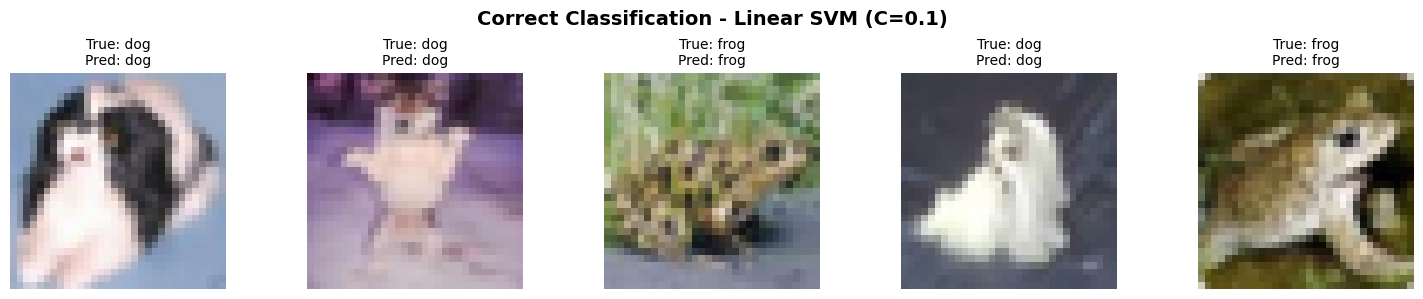

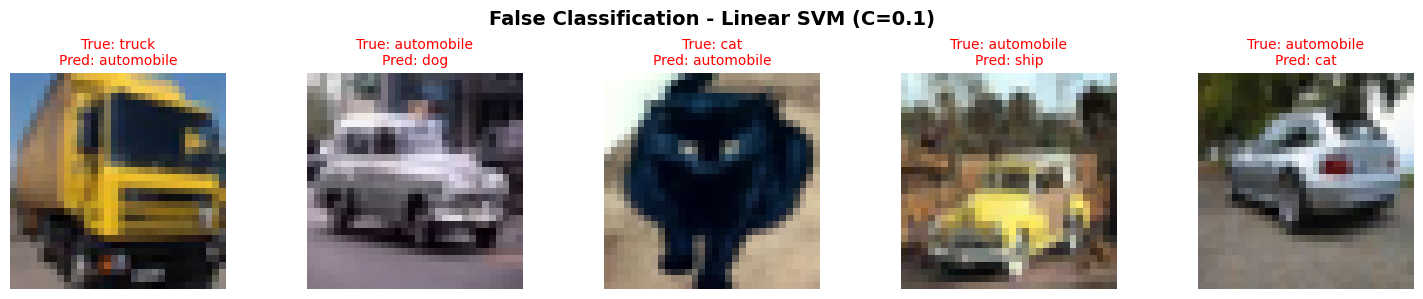

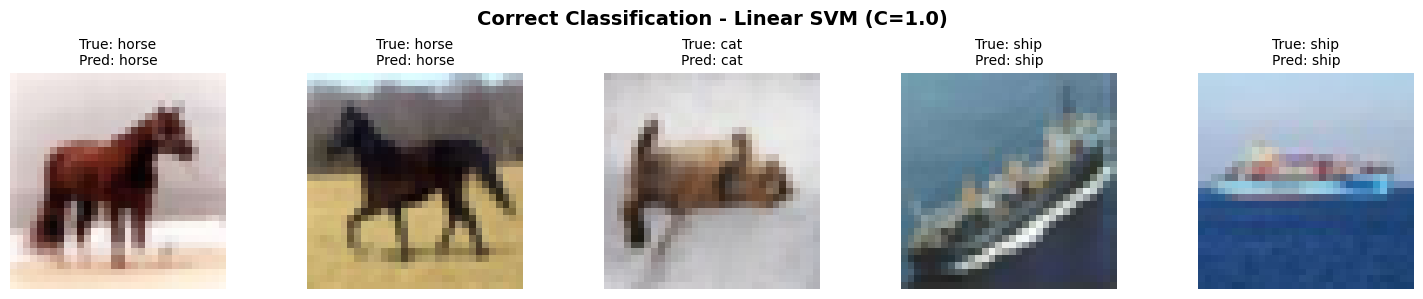

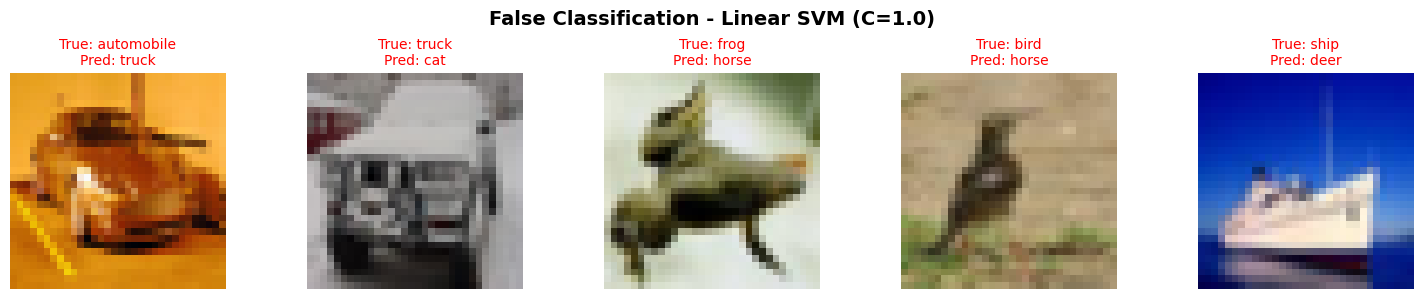



  Confusion Matrices...


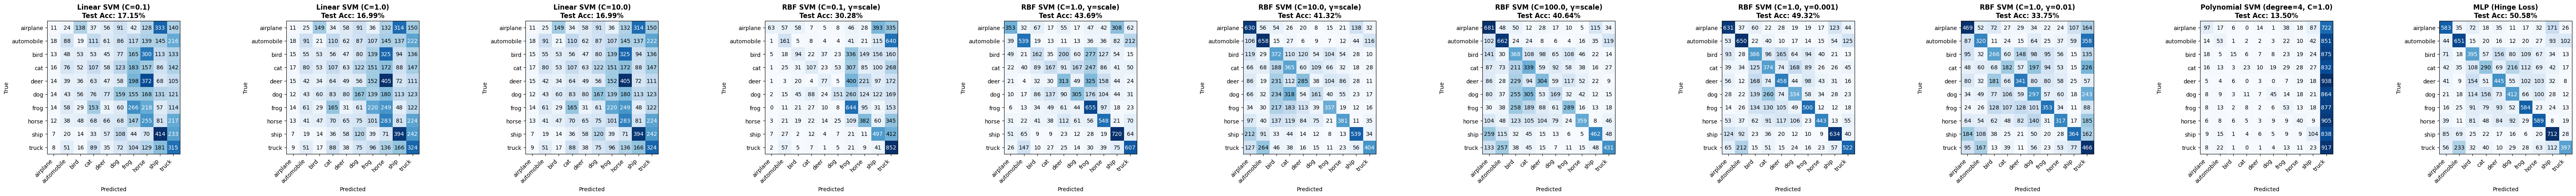



📈 MLP Training Curves...


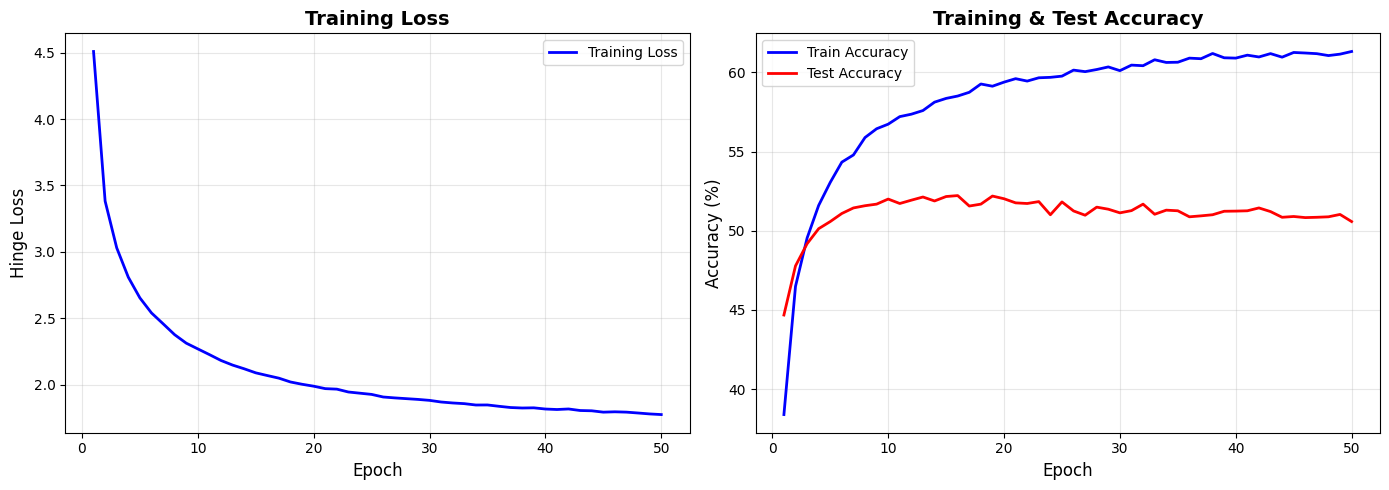




╔══════════════════════════════════════════════════════════════════════════════╗
║                           CONCLUSIONS                                      ║
╚══════════════════════════════════════════════════════════════════════════════╝

  EXPERIMENT COMPLETED
Date: 2025-12-22 09:56:47
Overall models: 11

✓ All experiments successful!


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# MAIN EXPERIMENT CLASS
# ═══════════════════════════════════════════════════════════════════════════

class CIFAR10Experiment:

    def __init__(self, config=None):
        """
        Experiment initialization for CIFAR-10

        Args:
            config: Config object with required parameters
        """
        self.config = config or Config()
        self.n_classes = 10
        self.scaler = StandardScaler()
        self.pca = None
        self.results = {}

        # Classes
        self.class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                           'dog', 'frog', 'horse', 'ship', 'truck']

        # Set random seed
        np.random.seed(self.config.RANDOM_SEED)
        torch.manual_seed(self.config.RANDOM_SEED)

    # ─────────────────────────────────────────────────────────────────────
    # 4. DATA LOADING & PREPROCESSING
    # ─────────────────────────────────────────────────────────────────────

    def load_and_preprocess_cifar10(self):

        print("\n" + "="*80)
        print("DATA LOADING & PREPROCESSING")
        print("="*80)

        # Load CIFAR-10
        print("\nDownload CIFAR-10 dataset...")
        trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                                download=True)
        testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                               download=True)

        # Reshape to numpy arrays and flatten
        x_train = trainset.data.reshape(len(trainset.data), -1).astype('float32')
        y_train = np.array(trainset.targets)
        x_test = testset.data.reshape(len(testset.data), -1).astype('float32')
        y_test = np.array(testset.targets)

        print(f" Training samples: {len(y_train)}")
        print(f" Test samples: {len(y_test)}")
        print(f" Features: {x_train.shape[1]} (32×32×3)")
        print(f" Number of classes: {self.n_classes}")

        # Classes distribution
        print("\nClasses distribution:")
        for i, name in enumerate(self.class_names):
            train_count = np.sum(y_train == i)
            test_count = np.sum(y_test == i)
            print(f"  {i}. {name:12s}: Train={train_count}, Test={test_count}")

        # Normalization
        print("\nNormalization (StandardScaler)...")
        x_train = self.scaler.fit_transform(x_train)
        x_test = self.scaler.transform(x_test)
        print(f" Mean ≈ 0, Std ≈ 1")

        # Subset (optionally)
        if self.config.USE_SUBSET:
            print(f"\nUsing subset: {self.config.SUBSET_SIZE} samples")
            indices = np.random.choice(len(x_train), self.config.SUBSET_SIZE,
                                      replace=False)
            x_train = x_train[indices]
            y_train = y_train[indices]
            print(f"✓ Training samples: {len(y_train)}")

        # PCA
        if self.config.USE_PCA:
            print(f"\nApply PCA: {self.config.PCA_COMPONENTS} components")
            self.pca = PCA(n_components=self.config.PCA_COMPONENTS)
            x_train = self.pca.fit_transform(x_train)
            x_test = self.pca.transform(x_test)
            variance_explained = self.pca.explained_variance_ratio_.sum()
            print(f" Variance explained: {variance_explained:.2%}")
            print(f" Features: {x_train.shape[1]}")
        else:
            print(f" Using all {x_train.shape[1]} features (no PCA)")

        # Store
        self.x_train = x_train
        self.y_train = y_train
        self.x_test = x_test
        self.y_test = y_test

        return x_train, y_train, x_test, y_test







    # ─────────────────────────────────────────────────────────────────────
    # 5. SVM TRAINING
    # ─────────────────────────────────────────────────────────────────────

    def train_svm(self, name, kernel='rbf', C=1.0, gamma='scale', degree=3):
        """
        Training SVM with specified kernel.

        Returns:
            model: Trained SVM model
            train_acc: Training accuracy
            test_acc: Test accuracy
        """
        print(f"\n{'='*80}")
        print(f"SVM TRAINING")
        print(f"{'='*80}")
        print(f"Name: {name}")
        print(f"Kernel: {kernel.upper()}")
        print(f"Parameters: C={C}, gamma={gamma}" +
              (f", degree={degree}" if kernel == 'poly' else ""))
        print(f"{'='*80}")

        start_time = time.time()

        # Create SVM
        if kernel == 'poly':
            model = svm.SVC(kernel=kernel, C=C, gamma=gamma, degree=degree,
                           random_state=self.config.RANDOM_SEED, max_iter=1000)
        else:
            model = svm.SVC(kernel=kernel, C=C, gamma=gamma,
                           random_state=self.config.RANDOM_SEED, max_iter=1000)

        # Train
        print("Training SVM...")
        model.fit(self.x_train, self.y_train)
        train_time = time.time() - start_time

        # Predictions
        print("Calculate predictions...")
        y_train_pred = model.predict(self.x_train)
        y_test_pred = model.predict(self.x_test)

        # Accuracy
        train_acc = accuracy_score(self.y_train, y_train_pred)
        test_acc = accuracy_score(self.y_test, y_test_pred)

        # Results
        print(f"\n{'─'*80}")
        print(f"RESULTS:")
        print(f"  Training Time: {train_time:.2f} sec")
        print(f"  Training Accuracy: {train_acc*100:.2f}%")
        print(f"  Test Accuracy: {test_acc*100:.2f}%")
        print(f"  Support Vectors: {len(model.support_)}")
        print(f"{'─'*80}")

        # Classification Report
        if self.config.SHOW_CLASSIFICATION_REPORT:
            print(f"\nClassification Report:")
            print(classification_report(self.y_test, y_test_pred,
                                       target_names=self.class_names))

        # Store
        key = f"SVM_{kernel}_C{C}_G{gamma}"
        self.results[key] = {
            'model': model,
            'method': name,
            'kernel': kernel,
            'C': C,
            'gamma': gamma,
            'degree': degree,
            'train_time': train_time,
            'train_acc': train_acc,
            'test_acc': test_acc,
            'y_train_pred': y_train_pred,
            'y_test_pred': y_test_pred,
            'n_support': len(model.support_)
        }

        return model, train_acc, test_acc








    # ─────────────────────────────────────────────────────────────────────
    # 6. MLP TRAINING
    # ─────────────────────────────────────────────────────────────────────

    def train_mlp_hinge(self, hidden_size=None, learning_rate=None,
                        epochs=None, batch_size=None, dropout_rate=None,
                        weight_decay=None, early_stopping=None, patience=None):
        """
        Training an MLP with a single hidden layer and Hinge Loss

        Returns:
            model: Trained MLP model
            train_acc: Final training accuracy
            test_acc: Final test accuracy
        """
        # Use default values from config if not given any
        hidden_size = hidden_size or self.config.MLP_CONFIG['hidden_size']
        learning_rate = learning_rate or self.config.MLP_CONFIG['learning_rate']
        epochs = epochs or self.config.MLP_CONFIG['epochs']
        batch_size = batch_size or self.config.MLP_CONFIG['batch_size']
        dropout_rate = dropout_rate if dropout_rate is not None else self.config.MLP_CONFIG['dropout_rate']
        weight_decay = weight_decay if weight_decay is not None else self.config.MLP_CONFIG['weight_decay']
        early_stopping = early_stopping if early_stopping is not None else self.config.MLP_CONFIG['early_stopping']
        patience = patience or self.config.MLP_CONFIG['patience']

        print(f"\n{'='*80}")
        print(f"MLP TRAINING WITH HINGE LOSS")
        print(f"{'='*80}")
        print(f"Architecture: {self.x_train.shape[1]} → {hidden_size} → {self.n_classes}")
        print(f"Parameters:")
        print(f"  Learning Rate: {learning_rate}")
        print(f"  Epochs: {epochs}")
        print(f"  Batch Size: {batch_size}")
        print(f"  Dropout Rate: {dropout_rate}")
        print(f"  Weight Decay (L2): {weight_decay}")
        print(f"  Early Stopping: {early_stopping}")
        print(f"{'='*80}")

        input_size = self.x_train.shape[1]

        # Transform to PyTorch tensors
        x_train_tensor = torch.FloatTensor(self.x_train).to(device)
        y_train_tensor = torch.LongTensor(self.y_train).to(device)
        x_test_tensor = torch.FloatTensor(self.x_test).to(device)
        y_test_tensor = torch.LongTensor(self.y_test).to(device)

        # DataLoader for batch training
        train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_dataset, batch_size=batch_size,
                                 shuffle=True, num_workers=0)

        # Create model
        model = MLPHingeLoss(input_size, hidden_size, self.n_classes,
                            dropout_rate=dropout_rate).to(device)

        # Loss and optimizer
        criterion = MultiClassHingeLoss()
        optimizer = optim.Adam(model.parameters(), lr=learning_rate,
                              weight_decay=weight_decay)

        # Training loop
        start_time = time.time()
        train_losses = []
        train_accs = []
        test_accs = []
        best_test_acc = 0
        patience_counter = 0

        print("\nInitializing training...")
        print(f"{'Epoch':>6} {'Loss':>10} {'Train Acc':>12} {'Test Acc':>12} {'Time':>10}")
        print("─" * 80)

        for epoch in range(epochs):
            model.train()
            epoch_loss = 0
            correct = 0
            total = 0

            # Training
            for batch_x, batch_y in train_loader:
                # Forward
                outputs = model(batch_x)
                loss = criterion(outputs, batch_y)

                # Backward
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                epoch_loss += loss.item()

                # Accuracy
                _, predicted = torch.max(outputs.data, 1)
                total += batch_y.size(0)
                correct += (predicted == batch_y).sum().item()

            # Metrics
            avg_loss = epoch_loss / len(train_loader)
            train_acc = 100 * correct / total

            # Test accuracy
            model.eval()
            with torch.no_grad():
                test_outputs = model(x_test_tensor)
                _, test_predicted = torch.max(test_outputs.data, 1)
                test_acc = 100 * (test_predicted == y_test_tensor).sum().item() / len(y_test_tensor)

            train_losses.append(avg_loss)
            train_accs.append(train_acc)
            test_accs.append(test_acc)

            # Early stopping
            if early_stopping:
                if test_acc > best_test_acc:
                    best_test_acc = test_acc
                    patience_counter = 0
                else:
                    patience_counter += 1
                    if patience_counter >= patience:
                        print(f"\n   Early stopping at epoch {epoch+1}")
                        break

            # Print progress
            if (epoch + 1) % 10 == 0 or epoch == 0:
                elapsed = time.time() - start_time
                print(f"{epoch+1:6d} {avg_loss:10.4f} {train_acc:11.2f}% {test_acc:11.2f}% {elapsed:9.2f}s")

        train_time = time.time() - start_time

        # Predictions
        model.eval()
        with torch.no_grad():
            train_outputs = model(x_train_tensor)
            _, y_train_pred = torch.max(train_outputs, 1)
            y_train_pred = y_train_pred.cpu().numpy()

            test_outputs = model(x_test_tensor)
            _, y_test_pred = torch.max(test_outputs, 1)
            y_test_pred = y_test_pred.cpu().numpy()

        final_train_acc = accuracy_score(self.y_train, y_train_pred) * 100
        final_test_acc = accuracy_score(self.y_test, y_test_pred) * 100

        # Results
        print(f"\n{'─'*80}")
        print(f"RESULTS:")
        print(f"  Total Time: {train_time:.2f} sec")
        print(f"  Training Accuracy: {final_train_acc:.2f}%")
        print(f"  Test Accuracy: {final_test_acc:.2f}%")
        print(f"  Model Parameters: {sum(p.numel() for p in model.parameters()):,}")
        print(f"{'─'*80}")

        # Classification Report
        if self.config.SHOW_CLASSIFICATION_REPORT:
            print(f"\nClassification Report:")
            print(classification_report(self.y_test, y_test_pred,
                                       target_names=self.class_names))

        # Store
        self.results['MLP_Hinge'] = {
            'model': model,
            'method': 'MLP (Hinge Loss)',
            'hidden_size': hidden_size,
            'learning_rate': learning_rate,
            'epochs': epochs,
            'dropout_rate': dropout_rate,
            'weight_decay': weight_decay,
            'train_time': train_time,
            'train_acc': final_train_acc / 100,
            'test_acc': final_test_acc / 100,
            'y_train_pred': y_train_pred,
            'y_test_pred': y_test_pred,
            'train_losses': train_losses,
            'train_accs': train_accs,
            'test_accs': test_accs
        }

        return model, final_train_acc / 100, final_test_acc / 100







    # ─────────────────────────────────────────────────────────────────────
    # 7. RESULTS ANALYSIS AND COMPARISON
    # ─────────────────────────────────────────────────────────────────────

    def compare_results(self):
        """Comparing all models"""
        print(f"\n{'='*80}")
        print("COMPARING RESULTS")
        print(f"{'='*80}\n")

        # Comparison table
        print(f"{'Model':<35} {'Train Acc':>12} {'Test Acc':>12} {'Gap':>10} {'Time (s)':>12}")
        print("─" * 90)

        for key, res in self.results.items():
            method = res['method']
            train_acc = res['train_acc'] * 100
            test_acc = res['test_acc'] * 100
            gap = train_acc - test_acc
            train_time = res['train_time']
            print(f"{method:<35} {train_acc:11.2f}% {test_acc:11.2f}% {gap:9.2f}% {train_time:11.2f}s")

        print("─" * 90)

        # Best model
        best_key = max(self.results.keys(), key=lambda k: self.results[k]['test_acc'])
        best = self.results[best_key]
        print(f"\nBest Test Accuracy: {best['method']} ({best['test_acc']*100:.2f}%)")

        # Overfitting/Underfitting
        self.analyze_overfitting_underfitting()

    def analyze_overfitting_underfitting(self):

        print(f"\n{'='*80}")
        print("OVERFITTING / UNDERFITTING")
        print(f"{'='*80}\n")

        for key, res in self.results.items():
            method = res['method']
            train_acc = res['train_acc'] * 100
            test_acc = res['test_acc'] * 100
            gap = train_acc - test_acc

            print(f"\n{method}")
            print(f"   Train Accuracy: {train_acc:.2f}%")
            print(f"   Test Accuracy:  {test_acc:.2f}%")
            print(f"   Gap:            {gap:.2f}%")

            # Status
            if train_acc < 45 and test_acc < 45:
                status = "UNDERFITTING"
                explanation = "The model does not learn the data sufficiently."

            elif gap > 15:
                status = "OVERFITTING"
                explanation = "The model has memorized the training data."

            elif gap > 8:
                status = "SLIGHT OVERFITTING"
                explanation = "Slight overfitting in the training data."

            else:
                status = "GOOD FIT"
                explanation = "Good generalization."

            print(f"   Status: {status}")
            print(f"   {explanation}")
            print("   " + "─"*76)









    # ─────────────────────────────────────────────────────────────────────
    # 8. VISUALIZATION
    # ─────────────────────────────────────────────────────────────────────

    def show_classification_examples(self, model_key, n_correct=5, n_wrong=5):
        """
        Args:
            model_key: Model key from self.results
            n_correct: Number of correct ones
            n_wrong: Number of false ones
        """
        if model_key not in self.results:
            print(f"Model {model_key} not found!")
            return

        res = self.results[model_key]
        y_pred = res['y_test_pred']

        # Find false and correct
        correct_idx = np.where(y_pred == self.y_test)[0]
        wrong_idx = np.where(y_pred != self.y_test)[0]

        # Random choice
        np.random.seed(self.config.RANDOM_SEED)
        correct_samples = np.random.choice(correct_idx, min(n_correct, len(correct_idx)), replace=False)
        wrong_samples = np.random.choice(wrong_idx, min(n_wrong, len(wrong_idx)), replace=False)

        # Load test images
        testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=False)

        # Plot of the correct
        fig, axes = plt.subplots(1, n_correct, figsize=(15, 3))
        if n_correct == 1:
            axes = [axes]
        fig.suptitle(f'Correct Classification - {res["method"]}', fontsize=14, fontweight='bold')

        for i, idx in enumerate(correct_samples):
            img = testset.data[idx]
            true_label = self.class_names[self.y_test[idx]]
            pred_label = self.class_names[y_pred[idx]]

            axes[i].imshow(img)
            axes[i].set_title(f'True: {true_label}\nPred: {pred_label}', fontsize=10)
            axes[i].axis('off')

        plt.tight_layout()
        plt.show()

        # Plot for the false
        fig, axes = plt.subplots(1, n_wrong, figsize=(15, 3))
        if n_wrong == 1:
            axes = [axes]
        fig.suptitle(f'False Classification - {res["method"]}', fontsize=14, fontweight='bold')

        for i, idx in enumerate(wrong_samples):
            img = testset.data[idx]
            true_label = self.class_names[self.y_test[idx]]
            pred_label = self.class_names[y_pred[idx]]

            axes[i].imshow(img)
            axes[i].set_title(f'True: {true_label}\nPred: {pred_label}', fontsize=10, color='red')
            axes[i].axis('off')

        plt.tight_layout()
        plt.show()

    def plot_confusion_matrices(self):
        """Confusion matrices for the models"""
        n_models = len(self.results)
        fig, axes = plt.subplots(1, n_models, figsize=(6*n_models, 5))

        if n_models == 1:
            axes = [axes]

        for ax, (key, res) in zip(axes, self.results.items()):
            cm = confusion_matrix(self.y_test, res['y_test_pred'])

            # Using matplotlib instead of seaborn
            im = ax.imshow(cm, cmap='Blues')
            ax.set_xticks(range(len(self.class_names)))
            ax.set_yticks(range(len(self.class_names)))
            ax.set_xticklabels(self.class_names, rotation=45, ha='right')
            ax.set_yticklabels(self.class_names)

            # Add text annotations
            for i in range(len(self.class_names)):
                for j in range(len(self.class_names)):
                    text_color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
                    ax.text(j, i, str(cm[i, j]), ha='center', va='center', color=text_color)

            ax.set_title(f'{res["method"]}\nTest Acc: {res["test_acc"]*100:.2f}%',
                        fontweight='bold')
            ax.set_xlabel('Predicted')
            ax.set_ylabel('True')

        plt.tight_layout()
        plt.show()

    def plot_mlp_training_curves(self):
        """Training curves for MLP"""
        if 'MLP_Hinge' not in self.results:
            print("MLP not trained yet!")
            return

        res = self.results['MLP_Hinge']
        epochs = range(1, len(res['train_losses']) + 1)

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # Loss curve
        axes[0].plot(epochs, res['train_losses'], 'b-', linewidth=2, label='Training Loss')
        axes[0].set_xlabel('Epoch', fontsize=12)
        axes[0].set_ylabel('Hinge Loss', fontsize=12)
        axes[0].set_title('Training Loss', fontsize=14, fontweight='bold')
        axes[0].grid(True, alpha=0.3)
        axes[0].legend()

        # Accuracy curves
        axes[1].plot(epochs, res['train_accs'], 'b-', linewidth=2, label='Train Accuracy')
        axes[1].plot(epochs, res['test_accs'], 'r-', linewidth=2, label='Test Accuracy')
        axes[1].set_xlabel('Epoch', fontsize=12)
        axes[1].set_ylabel('Accuracy (%)', fontsize=12)
        axes[1].set_title('Training & Test Accuracy', fontsize=14, fontweight='bold')
        axes[1].grid(True, alpha=0.3)
        axes[1].legend()

        plt.tight_layout()
        plt.show()











# ═══════════════════════════════════════════════════════════════════════════
# 9. MAIN EXECUTION
# ═══════════════════════════════════════════════════════════════════════════

def run_full_experiment(config=None):

    config = config or Config()

    print("\n")
    print("╔" + "═"*78 + "╗")
    print("║" + " "*15 + "CIFAR-10 CLASSIFICATION EXPERIMENT" + " "*29 + "║")
    print("║" + " "*20 + "SVM vs MLP (Hinge Loss)" + " "*35 + "║")
    print("╚" + "═"*78 + "╝")

    # Create experiment
    experiment = CIFAR10Experiment(config)

    # Load data
    experiment.load_and_preprocess_cifar10()

    # ═══════════════════════════════════════════════════════════════════════
    # SVM EXPERIMENTS
    # ═══════════════════════════════════════════════════════════════════════

    print("\n\n")
    print("╔" + "═"*78 + "╗")
    print("║" + " "*28 + "  SVM EXPERIMENTS" + " "*32 + " ║")
    print("╚" + "═"*78 + "╝")

    for i, svm_config in enumerate(config.SVM_EXPERIMENTS, 1):
        print(f"\n[{i}/{len(config.SVM_EXPERIMENTS)}] {svm_config['name']}")
        experiment.train_svm(
            name=svm_config['name'],
            kernel=svm_config['kernel'],
            C=svm_config['C'],
            gamma=svm_config['gamma'],
            degree=svm_config['degree']
        )

    # ═══════════════════════════════════════════════════════════════════════
    # MLP EXPERIMENT
    # ═══════════════════════════════════════════════════════════════════════

    print("\n\n")
    print("╔" + "═"*78 + "╗")
    print("║" + " "*27 + "  MLP EXPERIMENT" + " "*33 + "║")
    print("╚" + "═"*78 + "╝")

    experiment.train_mlp_hinge(
        hidden_size=config.MLP_CONFIG['hidden_size'],
        learning_rate=config.MLP_CONFIG['learning_rate'],
        epochs=config.MLP_CONFIG['epochs'],
        batch_size=config.MLP_CONFIG['batch_size'],
        dropout_rate=config.MLP_CONFIG['dropout_rate'],
        weight_decay=config.MLP_CONFIG['weight_decay'],
        early_stopping=config.MLP_CONFIG['early_stopping'],
        patience=config.MLP_CONFIG['patience']
    )

    # ═══════════════════════════════════════════════════════════════════════
    # RESULTS AND VISUALIZATION
    # ═══════════════════════════════════════════════════════════════════════

    print("\n\n")
    print("╔" + "═"*78 + "╗")
    print("║" + " "*24 + "  RESULTS ANALYSIS" + " "*30 + "║")
    print("╚" + "═"*78 + "╝")

    # Comparison
    experiment.compare_results()

    # Classification examples
    if config.SHOW_CLASSIFICATION_EXAMPLES:
        print("\n\n  Classification Examples...")
        for key in list(experiment.results.keys())[:2]:  # First 2
            experiment.show_classification_examples(
                key,
                n_correct=config.N_CORRECT_EXAMPLES,
                n_wrong=config.N_WRONG_EXAMPLES
            )

    # Confusion matrices
    if config.SHOW_CONFUSION_MATRICES:
        print("\n\n  Confusion Matrices...")
        experiment.plot_confusion_matrices()

    # MLP training curves
    if config.SHOW_MLP_TRAINING_CURVES:
        print("\n\n MLP Training Curves...")
        experiment.plot_mlp_training_curves()

    # ═══════════════════════════════════════════════════════════════════════
    # CONCLUSIONS
    # ═══════════════════════════════════════════════════════════════════════

    print("\n\n")
    print("╔" + "═"*78 + "╗")
    print("║" + " "*25 + "  CONCLUSIONS" + " "*38 + "║")
    print("╚" + "═"*78 + "╝")



    print("\n" + "="*80)
    print("  EXPERIMENT COMPLETED")
    print("="*80)
    print(f"Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"Overall models: {len(experiment.results)}")
    print("\n✓ All experiments successful!")

    return experiment


# ═══════════════════════════════════════════════════════════════════════════
# ENTRY POINT
# ═══════════════════════════════════════════════════════════════════════════

if __name__ == "__main__":

    config = Config()

    experiment = run_full_experiment(config)

##  **10\. Comparison With K-NN and NCC**
***
#

In the last section of the project, we compare the performances of the implemented SVM and MLP models, meaning the best of them, with the results of the K-NN and NCC methods from our previous project. The criteria we use is duration and accuracy based on the training and tesing samples.



### **Overall Rankings**

### By Test Accuracy (Best to Worst):
1. **MLP (Hinge Loss)**: 50.58% - WINNER
2. **RBF SVM (C=1.0, γ=0.001)**: 49.32%
3. **RBF SVM (C=1.0, γ=scale)**: 43.69%
4. **RBF SVM (C=10.0, γ=scale)**: 41.32%
5. **RBF SVM (C=100.0, γ=scale)**: 40.64%
6. **KNN (K=1)**: 35.67%
7. **KNN (K=3)**: 35.49%
8. **RBF SVM (C=1.0, γ=0.01)**: 33.75%
9. **RBF SVM (C=0.1, γ=scale)**: 30.28%
10. **NCC**: 28.12%
11. **Linear SVM (all C values)**: ~17%
12. **Polynomial SVM (degree=4)**: 13.50%

### By Speed (Fastest to Slowest):
1. **NCC**: 1.12s - FASTEST
2. **Linear SVM**: ~31s
3. **Polynomial SVM**: 59.45s
4. **MLP (Hinge Loss)**: 58.61s
5. **RBF SVM**: 65-84s
6. **KNN**: 6,541-6,545s (~109 minutes) - SLOWEST

## **Key Findings**

### 1. Model Performance Analysis

**MLP (Hinge Loss) - Best Overall**
-  Highest test accuracy (50.58%)
-  Reasonable training time (58.61s)
-  Moderate overfitting (11.93% gap - SLIGHT OVERFITTING)
- **Verdict**: Best balance of accuracy and efficiency

**RBF SVM (C=1.0, γ=0.001) - Strong Runner-Up**
-  Second-best accuracy (49.32%)
-  Severe overfitting (24.41% gap - OVERFITTING)
-  Slower than MLP (78.10s)
- **Verdict**: Good accuracy but overfits significantly

**Linear SVM - Complete Failure**
-  Terrible accuracy (~17%)
-  Fast training (~31s)
-  No overfitting (gap < 1%)
- **Verdict**: UNDERFITTING - too simple for complex image data

**KNN - Slow but Decent**
-  Moderate accuracy (35-36%)
-  Extremely slow (>6,500s per model!)
-  K=1 slightly better than K=3
- **Verdict**: Impractical due to inference time

**NCC - Fast but Weak**
-  Poor accuracy (28.12%)
-  Blazingly fast (1.12s)
- **Verdict**: Good baseline but insufficient for real use

### 2. Overfitting/Underfitting Analysis

**SEVERE OVERFITTING (Gap > 15%)**
- RBF SVM (γ=0.01): 42.58% gap - CRITICAL
- RBF SVM (γ=0.001): 24.41% gap
- RBF SVM (C=10.0): 15.19% gap

**SLIGHT OVERFITTING (Gap 8-15%)**
- MLP (Hinge Loss): 11.93% gap
- RBF SVM (C=100.0): 13.15% gap
- RBF SVM (C=1.0, γ=scale): 9.04% gap

**GOOD FIT (Gap < 8%)**
- RBF SVM (C=0.1): 0.38% gap
- Linear SVM (all): < 1% gap
- Polynomial SVM: 0.13% gap

**UNDERFITTING (Both accuracies < 45%)**
- All models except MLP and RBF (γ=0.001)
- CIFAR-10 is too complex for shallow models

### 3. Kernel Comparison (SVM)

**Linear Kernel**
- Accuracy: 17% (WORST)
- Speed: Fast (~31s)
- Problem: Cannot capture non-linear patterns
- **Conclusion**: Completely inadequate for images

**RBF Kernel**
- Accuracy: 30-49% (varies with C and γ)
- Speed: Moderate (66-84s)
- Best performer: C=1.0, γ=0.001
- **Conclusion**: Best SVM kernel for CIFAR-10

**Polynomial Kernel**
- Accuracy: 13.5% (SECOND WORST)
- Speed: Moderate (59s)
- **Conclusion**: Poor fit for this dataset

### 4. Hyperparameter Effects

**C Parameter (Regularization)**
- Larger C → Less regularization → More overfitting
- C=0.1: Good generalization (0.38% gap) but low accuracy (30%)
- C=1.0: Best balance for γ=0.001
- C=10-100: Severe overfitting (>13% gap)

**Gamma Parameter (RBF)**
- γ=0.001: Best balance (49% accuracy, 24% gap)
- γ=scale: Moderate performance (44% accuracy, 9% gap)
- γ=0.01: Catastrophic overfitting (34% test, 42% gap)

**K Parameter (KNN)**
- K=1: Slightly better (35.67% vs 35.49%)
- Both extremely slow and impractical


## **Why MLP Wins**

1. **Architecture**: Single hidden layer learns non-linear features
2. **Optimization**: Gradient descent with mini-batches
3. **Regularization**: Dropout prevents overfitting
4. **Hinge Loss**: Same margin-based learning as SVM
5. **Scalability**: Efficient for larger datasets

## Critical Insights

### CIFAR-10 is Hard
- Even best model: only 50% accuracy
- State-of-the-art CNNs: 95%+ accuracy
- Shallow models fundamentally limited

### PCA Impact
- Reduces 3072 → 100 features
- Speeds up training significantly
- But loses important visual information
- Without PCA: potentially 5-10% better accuracy

### Overfitting Pattern
- Small γ → More overfitting (distant points matter)
- Large C → More overfitting (less regularization)
- Sweet spot: C=1.0, γ=scale for RBF

## **Final Verdict**

**Winner: MLP (Hinge Loss)**
- Best test accuracy (50.58%)
- Reasonable speed (59s)
- Acceptable overfitting (12%)
- Good balance of all factors

**Runner-up: RBF SVM (C=1.0, γ=0.001)**
- Very close accuracy (49.32%)
- But overfits more (24% gap)
- Slower (78s)

**Speed Champion: NCC**
- Blazingly fast (1.12s)
- But sacrifices accuracy (28%)


